# Portfolio Assessment 3: Advanced ML - LSTM for Regression - Option 3b
Le Mai Chi | 105555880

This notebook is Appendix A of the report. It holds the code and stored outputs; the report holds the discussion.

In [1]:
from pathlib import Path
import os, sys, time, pickle
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # hide TensorFlow C++ log noise
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

print("Python      :", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("tensorflow  :", tf.__version__)

SEED = 42
keras.utils.set_random_seed(SEED)  # python, numpy and tensorflow
tf.config.experimental.enable_op_determinism()

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

DATA = Path("../output/nasa_battery_eda_clean.csv")
OUT = Path("output/")
FIG_DIR, TAB_DIR, MODEL_DIR = OUT / "figures", OUT / "tables", OUT / "models"
for d in (FIG_DIR, TAB_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

def save_table(df, name):
    df.to_csv(TAB_DIR / f"{name}.csv", index=False)
    return df

Python      : 3.12.13
scikit-learn: 1.9.1
tensorflow  : 2.21.0


## Part A: Traditional Machine Learning
### A.1 Load and analyse the dataset

In [2]:
df = pd.read_csv(DATA)
print("Shape:", df.shape, "| batteries:", df["battery_id"].nunique())
print("Columns:", list(df.columns))

assert pd.api.types.is_float_dtype(df["Capacity"])
print(f"Target Capacity: continuous, {df['Capacity'].nunique()} unique values in "
      f"[{df['Capacity'].min():.3f}, {df['Capacity'].max():.3f}] Ah -> regression")
display(df["Capacity"].describe().to_frame("Capacity (Ah)").T)

PREDICTORS = [
    "discharge_index", "ambient_temperature",
    "mean_voltage", "min_voltage", "max_voltage", "voltage_std", "voltage_drop",
    "mean_abs_current", "max_abs_current", "current_std",
    "mean_temperature", "max_temperature", "temperature_rise",
    "mean_abs_load_current", "mean_load_voltage",
]
EXCLUDED = ["capacity_class", "n_samples", "discharge_duration_s", "test_id", "uid", "filename"]
assert not set(PREDICTORS) & set(EXCLUDED + ["Capacity", "battery_id"]), "leaky column"
print("Predictors:", len(PREDICTORS), "| excluded:", EXCLUDED)

Shape: (2750, 23) | batteries: 34
Columns: ['n_samples', 'discharge_duration_s', 'mean_voltage', 'min_voltage', 'max_voltage', 'voltage_std', 'voltage_drop', 'mean_abs_current', 'max_abs_current', 'current_std', 'mean_temperature', 'max_temperature', 'temperature_rise', 'mean_abs_load_current', 'mean_load_voltage', 'battery_id', 'test_id', 'uid', 'filename', 'ambient_temperature', 'Capacity', 'discharge_index', 'capacity_class']
Target Capacity: continuous, 2750 unique values in [0.033, 2.640] Ah -> regression


,count,mean,std,min,25%,50%,75%,max
Capacity (Ah),2750.0000,1.3357,0.4611,0.0326,1.1564,1.4306,1.6744,2.6401


Predictors: 15 | excluded: ['capacity_class', 'n_samples', 'discharge_duration_s', 'test_id', 'uid', 'filename']


### A.2 Preprocess

In [3]:
X, y, groups = df[PREDICTORS], df["Capacity"], df["battery_id"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]
train_bats, test_bats = sorted(g_train.unique()), sorted(groups.iloc[test_idx].unique())
assert set(train_bats).isdisjoint(test_bats), "battery leakage"

# The scaler is refitted inside every fit, so it only sees training rows
def make_pipe(model):
    return Pipeline([("scale", StandardScaler()), ("model", model)])

shapes = save_table(pd.DataFrame({
    "split": ["train", "test"],
    "batteries": [len(train_bats), len(test_bats)],
    "samples": [len(X_train), len(X_test)],
    "features": [X_train.shape[1], X_test.shape[1]],
}), "table_1_split_shapes")
display(shapes)
print("Test batteries:", test_bats)

,split,batteries,samples,features
0,train,23,1821,15
1,test,11,929,15


Test batteries: ['B0005', 'B0029', 'B0030', 'B0033', 'B0038', 'B0042', 'B0044', 'B0047', 'B0049', 'B0050', 'B0055']


### A.3 Train 2 traditional models

In [4]:
models = {
    "Random Forest": make_pipe(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)),
    "MLP": make_pipe(MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=2000, random_state=SEED)),
}
preds = {name: m.fit(X_train, y_train).predict(X_test) for name, m in models.items()}

### A.4 Evaluate and compare

In [5]:
def metrics(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "RMSE": root_mean_squared_error(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred)}

CV = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)

rows = []
for name, m in models.items():
    cv = cross_val_score(m, X_train, y_train, groups=g_train, cv=CV, scoring="r2")
    rows.append({"model": name, "cv_R2_mean": cv.mean(), "cv_R2_sd": cv.std(),
                 **{f"test_{k}": v for k, v in metrics(y_test, preds[name]).items()}})
trad_table = save_table(pd.DataFrame(rows).round(4), "table_2_traditional_comparison")
display(trad_table)

BEST_A = trad_table.loc[trad_table["cv_R2_mean"].idxmax(), "model"]
print("Best traditional model by grouped-CV R2:", BEST_A)

,model,cv_R2_mean,cv_R2_sd,test_R2,test_RMSE,test_MAE
0,Random Forest,0.7566,0.2020,0.5249,0.3418,0.1377
1,MLP,0.6311,0.2426,0.6552,0.2912,0.1531


Best traditional model by grouped-CV R2: Random Forest


### A.5 Visualise

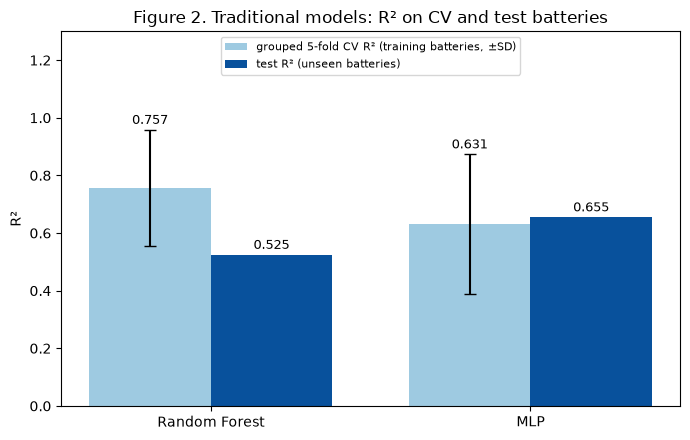

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(trad_table)); w = 0.38
ax.bar(x - w / 2, trad_table["cv_R2_mean"], w, yerr=trad_table["cv_R2_sd"], capsize=4,
       color="#9ecae1", label="grouped 5-fold CV R² (training batteries, ±SD)")
ax.bar(x + w / 2, trad_table["test_R2"], w, color="#08519c", label="test R² (unseen batteries)")
for i, r in trad_table.iterrows():
    ax.text(i - w / 2, max(r["cv_R2_mean"] + r["cv_R2_sd"], 0) + 0.02, f'{r["cv_R2_mean"]:.3f}', ha="center", fontsize=9)
    ax.text(i + w / 2, max(r["test_R2"], 0) + 0.02, f'{r["test_R2"]:.3f}', ha="center", fontsize=9)
ax.set_xticks(x, trad_table["model"])
ax.set_ylim(min(0, (trad_table["cv_R2_mean"] - trad_table["cv_R2_sd"]).min() - 0.05), 1.3)
ax.set_ylabel("R²")
ax.legend(loc="upper center", fontsize=8)
ax.set_title("Figure 2. Traditional models: R² on CV and test batteries")
plt.tight_layout()
save_fig("figure_02_traditional_r2")
plt.show()

## Part B: LSTM for Regression

### B.1 Prepare sequential data

In [13]:
seq = df.sort_values(["battery_id", "discharge_index"]).reset_index(drop=True)
step = seq.groupby("battery_id")["discharge_index"].diff()
breaks = seq.loc[step > 1, ["battery_id", "discharge_index"]].assign(missing=(step[step > 1] - 1).astype(int))
print(f"Index breaks: {len(breaks)} across {breaks['battery_id'].nunique()} batteries "
      f"(missing discharges per break: median {breaks['missing'].median():.0f}, max {breaks['missing'].max()})")
display(breaks.T)
# Breaks are kept: windows follow the observed order and discharge_index stays an input, so each jump is visible

# Past Capacity is not an input: with it the LSTM reduces to a persistence forecast, and Part A has no Capacity input
USE_PAST_CAPACITY = False
SEQ_FEATURES = PREDICTORS + (["Capacity"] if USE_PAST_CAPACITY else [])
N_FEATURES = len(SEQ_FEATURES)

def make_windows(frame, L):
    """Windows of L consecutive discharges inside each battery; label = Capacity of the next discharge."""
    X, y, idx = [], [], []
    for _, b in frame.groupby("battery_id", sort=False):
        feats, target = b[SEQ_FEATURES].to_numpy(np.float32), b["target"].to_numpy(np.float32)
        for t in range(L, len(b)):
            X.append(feats[t - L:t]); y.append(target[t]); idx.append(b.index[t])
    return np.array(X).reshape(-1, L, N_FEATURES), np.array(y), np.array(idx)

cycles = seq.groupby("battery_id").size().sort_values()
split_of = lambda b: "test" if b in test_bats else "train"
L_GRID = [5, 10, 20, 50]
win_table = save_table(pd.DataFrame([{
    "L": L,
    "usable_batteries": int((cycles > L).sum()),
    "windows": int((cycles - L).clip(lower=0).sum()),
    "train_windows": int(sum(max(n - L, 0) for b, n in cycles.items() if split_of(b) == "train")),
    "test_windows": int(sum(max(n - L, 0) for b, n in cycles.items() if split_of(b) == "test")),
} for L in L_GRID]), "table_B1_windows_per_L")
display(win_table)

Index breaks: 17 across 10 batteries (missing discharges per break: median 1, max 1)


,1712,1823,1934,2059,2104,2129,2162,2173,2198,2231,2242,2267,2300,2311,2333,2357,2377
battery_id,B0042,B0043,B0044,B0045,B0045,B0046,B0046,B0046,B0047,B0047,B0047,B0048,B0048,B0048,B0049,B0050,B0051
discharge_index,7,7,7,21,67,21,55,67,21,55,67,21,55,67,18,18,18
missing,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


,L,usable_batteries,windows,train_windows,test_windows
0,5,33,2581,1707,874
1,10,33,2416,1597,819
2,20,32,2086,1377,709
3,50,19,1315,857,458


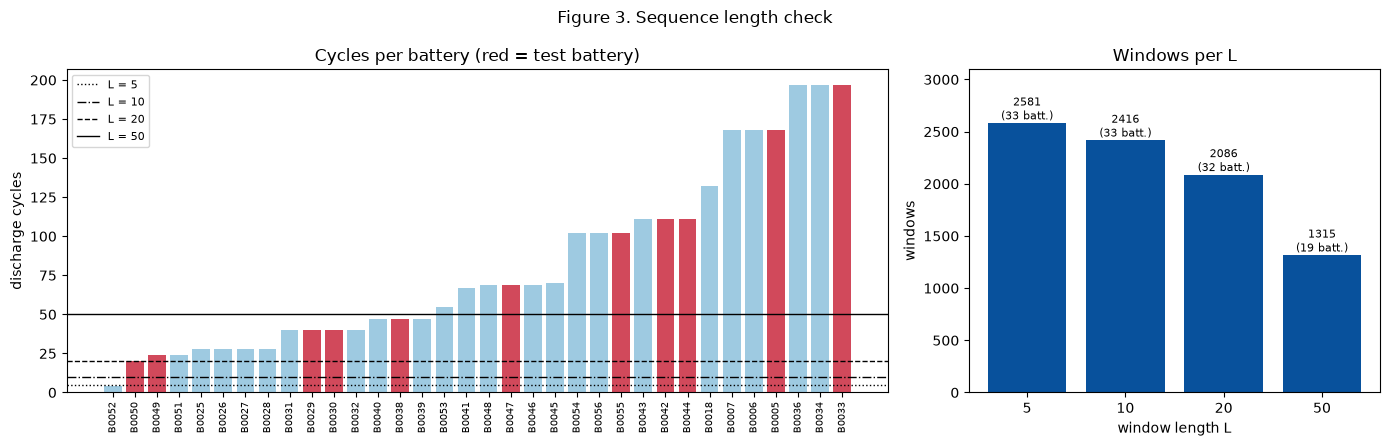

Validation batteries: ['B0006', 'B0032', 'B0034', 'B0045', 'B0048']


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].bar(cycles.index, cycles.values, color=["#d1495b" if b in test_bats else "#9ecae1" for b in cycles.index])
for L, ls in zip(L_GRID, [":", "-.", "--", "-"]):
    axes[0].axhline(L, ls=ls, lw=1, color="black", label=f"L = {L}")
axes[0].legend(loc="upper left", fontsize=8)
axes[0].tick_params(axis="x", rotation=90, labelsize=7)
axes[0].set_ylabel("discharge cycles")
axes[0].set_title("Cycles per battery (red = test battery)")
axes[1].bar(win_table["L"].astype(str), win_table["windows"], color="#08519c")
for i, r in win_table.iterrows():
    axes[1].text(i, r["windows"], f'{r["windows"]}\n({r["usable_batteries"]} batt.)', ha="center", va="bottom", fontsize=8)
axes[1].set_ylim(0, win_table["windows"].max() * 1.2)
axes[1].set_xlabel("window length L"); axes[1].set_ylabel("windows")
axes[1].set_title("Windows per L")
fig.suptitle("Figure 3. Sequence length check")
plt.tight_layout()
save_fig("figure_03_windows_per_L")
plt.show()

tb = np.array(train_bats)
fit_i, val_i = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED).split(tb, groups=tb))
fit_bats, val_bats = tb[fit_i], tb[val_i]
print("Validation batteries:", [str(b) for b in val_bats])

fit_rows = seq["battery_id"].isin(fit_bats)
x_scaler = MinMaxScaler().fit(seq.loc[fit_rows, SEQ_FEATURES])
y_scaler = MinMaxScaler().fit(seq.loc[fit_rows, ["Capacity"]])
scaled = seq.copy()
scaled[SEQ_FEATURES] = x_scaler.transform(seq[SEQ_FEATURES])
scaled["target"] = y_scaler.transform(seq[["Capacity"]]).ravel()


In [15]:
def make_split(L):
    return {name: make_windows(scaled[scaled["battery_id"].isin(bats)], L)
            for name, bats in [("train", fit_bats), ("val", val_bats), ("test", test_bats)]}

L1, L2 = 10, 5
dl1, dl2 = make_split(L1), make_split(L2)
display(pd.DataFrame([{"L": L, "split": s, "batteries": len(b), "X_shape (samples, timesteps, features)": data[s][0].shape,
                       "y_shape": data[s][1].shape}
                      for L, data in [(L1, dl1), (L2, dl2)]
                      for s, b in [("train", fit_bats), ("val", val_bats), ("test", test_bats)]]))

,L,split,batteries,"X_shape (samples, timesteps, features)",y_shape
0,10,train,18,"(1103, 10, 15)","(1103,)"
1,10,val,5,"(494, 10, 15)","(494,)"
2,10,test,11,"(819, 10, 15)","(819,)"
3,5,train,18,"(1188, 5, 15)","(1188,)"
4,5,val,5,"(519, 5, 15)","(519,)"
5,5,test,11,"(874, 5, 15)","(874,)"


### B.2 Build the LSTM architecture

In [21]:
def build_lstm(L, n_features):
    model = keras.Sequential([
        keras.Input(shape=(L, n_features)),
        keras.layers.LSTM(64, return_sequences=True),
        keras.layers.Dropout(0.2),
        keras.layers.LSTM(32),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1, activation="linear"),
    ], name=f"lstm_L{L}")
    model.compile(optimizer=keras.optimizers.Adam(), loss="mse", metrics=["mae"])
    return model

build_lstm(L1, N_FEATURES).summary()

Model: "lstm_L10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_10 (LSTM)                  │ (None, 10, 64)         │        20,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 10, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,441 (130.63 KB)

 Trainable params: 33,441 (130.63 KB)

 Non-trainable params: 0 (0.00 B)

### B.3 Train the model

In [23]:
BATCH_SIZES = [16, 32, 64]
EPOCHS = 50

def train_lstm(data, L, batch_size):
    keras.utils.set_random_seed(SEED)
    model = build_lstm(L, N_FEATURES)
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5)]
    start = time.time()
    hist = model.fit(*data["train"][:2], validation_data=data["val"][:2], epochs=EPOCHS,
                     batch_size=batch_size, callbacks=callbacks, verbose=0)
    return model, hist.history, time.time() - start

def run_summary(h, **extra):
    best = int(np.argmin(h["val_loss"]))
    return {**extra, "epochs_run": len(h["loss"]), "best_epoch": best + 1,
            "train_loss_at_best": h["loss"][best], "best_val_loss_mse": h["val_loss"][best],
            "val_mae_at_best": h["val_mae"][best]}

runs = {bs: train_lstm(dl1, L1, bs) for bs in BATCH_SIZES}
bs_table = save_table(pd.DataFrame([run_summary(h, L=L1, batch_size=bs, train_time_s=t)
for bs, (_, h, t) in runs.items()]).round(5), "table_3_batch_size")
display(bs_table)

,L,batch_size,train_time_s,epochs_run,best_epoch,train_loss_at_best,best_val_loss_mse,val_mae_at_best
0,10,16,12.7439,26,16,0.0039,0.0014,0.0282
1,10,32,7.1630,17,7,0.0073,0.0011,0.0258
2,10,64,6.9152,24,14,0.0059,0.0009,0.0234


Chosen batch size (lowest validation loss): 64
Deep Learning 2 (L = 5):


,L,batch_size,train_time_s,epochs_run,best_epoch,train_loss_at_best,best_val_loss_mse,val_mae_at_best
0,5,64,6.1827,18,8,0.0088,0.0021,0.0391


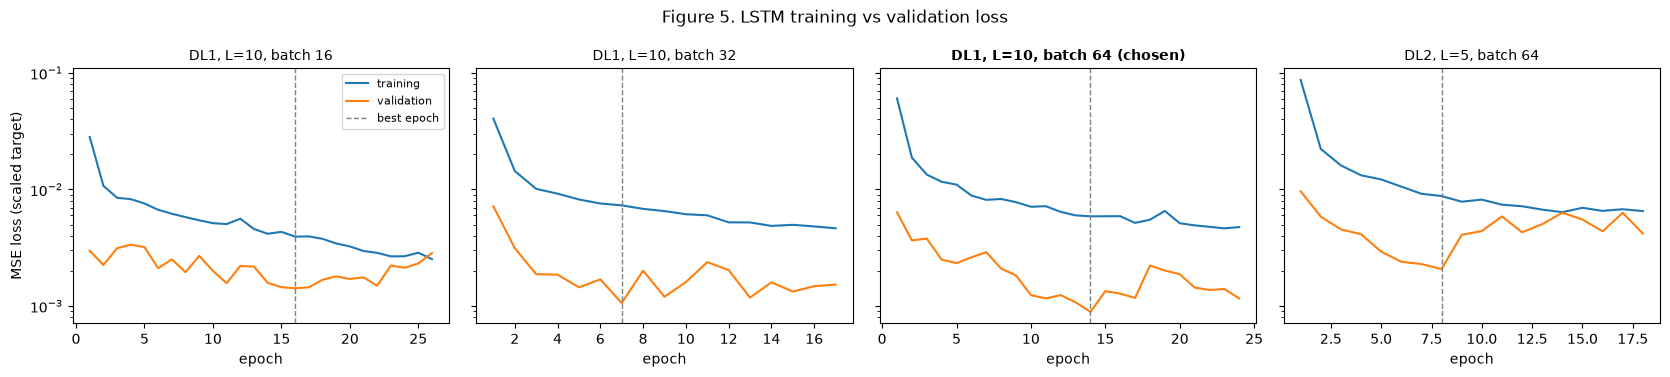

In [24]:
BEST_BS = int(bs_table.loc[bs_table["best_val_loss_mse"].idxmin(), "batch_size"])
lstm1, hist1, _ = runs[BEST_BS]
print("Chosen batch size (lowest validation loss):", BEST_BS)

lstm2, hist2, time2 = train_lstm(dl2, L2, BEST_BS)
dl2_summary = pd.DataFrame([run_summary(hist2, L=L2, batch_size=BEST_BS, train_time_s=time2)]).round(5)
print("Deep Learning 2 (L = 5):")
display(dl2_summary)

curves = [(f"DL1, L={L1}, batch {bs}" + (" (chosen)" if bs == BEST_BS else ""), h) for bs, (_, h, _) in runs.items()]
curves.append((f"DL2, L={L2}, batch {BEST_BS}", hist2))
fig, axes = plt.subplots(1, len(curves), figsize=(4.2 * len(curves), 3.8), sharey=True)
for ax, (title, h) in zip(axes, curves):
    ax.plot(range(1, len(h["loss"]) + 1), h["loss"], label="training")
    ax.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label="validation")
    ax.axvline(int(np.argmin(h["val_loss"])) + 1, ls="--", color="grey", lw=1, label="best epoch")
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_title(title, fontsize=10,
                                                                fontweight="bold" if "chosen" in title else "normal")
axes[0].set_ylabel("MSE loss (scaled target)")
axes[0].legend(fontsize=8)
fig.suptitle("Figure 5. LSTM training vs validation loss")
plt.tight_layout()
save_fig("figure_05_lstm_loss")
plt.show()

### B.4 Evaluate the LSTM

,R2,RMSE,MAE,test_windows
LSTM DL1 (L=10),0.7147,0.2690,0.1420,819
Random Forest on DL1 target rows,0.5054,0.3542,0.1379,819
LSTM DL2 (L=5),0.6054,0.3127,0.1789,874
Random Forest on DL2 target rows,0.5172,0.3459,0.1359,874


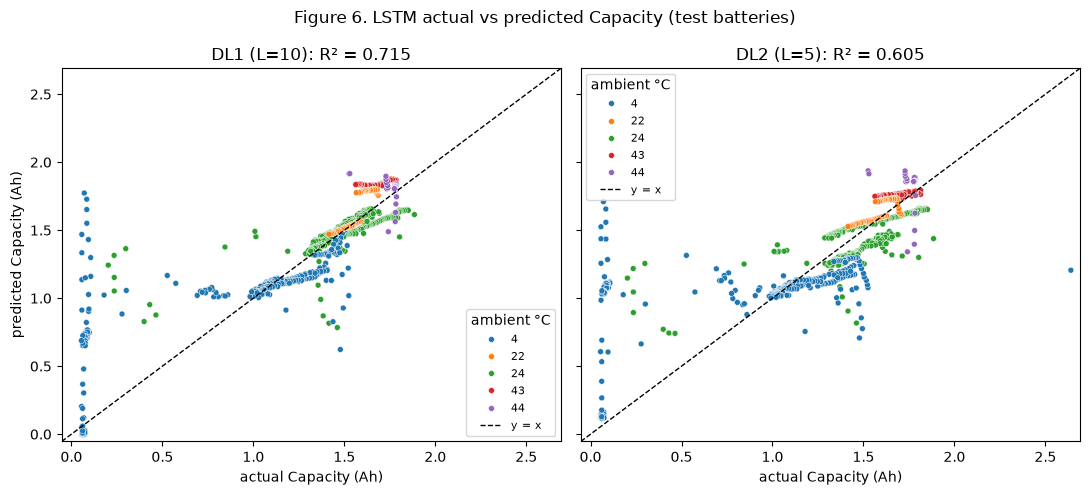

In [25]:
best_a = models[BEST_A]

def predict_ah(model, data):
    X_te, _, idx = data["test"]
    pred = y_scaler.inverse_transform(model.predict(X_te, verbose=0)).ravel()
    return seq.loc[idx].assign(pred=pred, pred_A=best_a.predict(seq.loc[idx, PREDICTORS]))

res1, res2 = predict_ah(lstm1, dl1), predict_ah(lstm2, dl2)

lstm_scores = pd.DataFrame({
    f"LSTM DL1 (L={L1})": metrics(res1["Capacity"], res1["pred"]),
    f"{BEST_A} on DL1 target rows": metrics(res1["Capacity"], res1["pred_A"]),
    f"LSTM DL2 (L={L2})": metrics(res2["Capacity"], res2["pred"]),
    f"{BEST_A} on DL2 target rows": metrics(res2["Capacity"], res2["pred_A"]),
}).T
lstm_scores["test_windows"] = [len(res1), len(res1), len(res2), len(res2)]
display(lstm_scores)

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
lims = [min(seq["Capacity"].min(), res1["pred"].min(), res2["pred"].min()) - 0.05,
        max(seq["Capacity"].max(), res1["pred"].max(), res2["pred"].max()) + 0.05]
temps = [str(t) for t in sorted(seq["ambient_temperature"].unique())]
for ax, (title, res) in zip(axes, [(f"DL1 (L={L1})", res1), (f"DL2 (L={L2})", res2)]):
    sns.scatterplot(data=res, x="Capacity", y="pred", hue=res["ambient_temperature"].astype(str),
                    hue_order=temps, palette="tab10", s=18, ax=ax)
    ax.plot(lims, lims, "k--", lw=1, label="y = x")
    r2 = r2_score(res["Capacity"], res["pred"])
    ax.set_title(f"{title}: R² = {r2:.3f}")
    ax.set_xlabel("actual Capacity (Ah)"); ax.set_ylabel("predicted Capacity (Ah)")
    ax.legend(title="ambient °C", fontsize=8)
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
fig.suptitle("Figure 6. LSTM actual vs predicted Capacity (test batteries)")
plt.tight_layout()
save_fig("figure_06_lstm_actual_vs_pred")
plt.show()

In [26]:
per_temp = save_table(
    (
        res1.groupby("ambient_temperature")[
            ["battery_id", "Capacity", "pred", "pred_A"]
        ]
        .apply(
            lambda g: pd.Series({
                "batteries": g["battery_id"].nunique(),
                "windows": len(g),
                "LSTM_RMSE": root_mean_squared_error(g["Capacity"], g["pred"]),
                "LSTM_MAE": mean_absolute_error(g["Capacity"], g["pred"]),
                f"{BEST_A}_RMSE": root_mean_squared_error(g["Capacity"], g["pred_A"]),
                f"{BEST_A}_MAE": mean_absolute_error(g["Capacity"], g["pred_A"])
            })
        )
        .reset_index()
        .round(4)
        .astype({"batteries": int, "windows": int})
    ),
    "table_4_errors_by_temperature"
)

print(f"Errors by ambient temperature, DL1 test windows (L={L1}):")
display(per_temp)

Errors by ambient temperature, DL1 test windows (L=10):


,ambient_temperature,batteries,windows,LSTM_RMSE,LSTM_MAE,Random Forest_RMSE,Random Forest_MAE
0,4,6,317,0.3823,0.2147,0.5637,0.2872
1,22,2,60,0.1123,0.0873,0.0476,0.0373
2,24,3,347,0.1676,0.0861,0.0668,0.0433
3,43,2,60,0.1762,0.1693,0.0654,0.0586
4,44,1,35,0.1260,0.0844,0.0439,0.0302


### B.5 Save the models

In [27]:
lstm1.save(MODEL_DIR / "lstm_dl1.h5")
lstm2.save(MODEL_DIR / "lstm_dl2.h5")
for name, h in {"dl1": hist1, "dl2": hist2}.items():
    with open(MODEL_DIR / f"lstm_{name}_history.pkl", "wb") as f:
        pickle.dump(h, f)

# StandardScalers are saved inside the RF and MLP pipelines
joblib.dump(models["Random Forest"], MODEL_DIR / "random_forest.pkl")
joblib.dump(models["MLP"], MODEL_DIR / "mlp.pkl")
joblib.dump({"x": x_scaler, "y": y_scaler, "features": SEQ_FEATURES}, MODEL_DIR / "lstm_minmax_scalers.pkl")
print(sorted(p.name for p in MODEL_DIR.iterdir()))

['lstm_dl1.h5', 'lstm_dl1_history.pkl', 'lstm_dl2.h5', 'lstm_dl2_history.pkl', 'lstm_minmax_scalers.pkl', 'mlp.pkl', 'random_forest.pkl']


## Part C: Final Summary and Reflection

### C.1 Master results table

In [28]:
one_row = "1 discharge × 15 features"
master = pd.DataFrame([
    {"model": "Random Forest", "input": one_row, "evaluated_on": "all test rows", "n": len(y_test),
     **metrics(y_test, preds["Random Forest"])},
    {"model": "MLP", "input": one_row, "evaluated_on": "all test rows", "n": len(y_test),
     **metrics(y_test, preds["MLP"])},
    {"model": f"{BEST_A} (DL1 rows)", "input": one_row, "evaluated_on": f"DL1 target rows", "n": len(res1),
     **metrics(res1["Capacity"], res1["pred_A"])},
    {"model": f"LSTM (DL1, L={L1})", "input": f"{L1} previous discharges × {N_FEATURES} features",
     "evaluated_on": "DL1 target rows", "n": len(res1), **metrics(res1["Capacity"], res1["pred"])},
    {"model": f"{BEST_A} (DL2 rows)", "input": one_row, "evaluated_on": f"DL2 target rows", "n": len(res2),
     **metrics(res2["Capacity"], res2["pred_A"])},
    {"model": f"LSTM (DL2, L={L2})", "input": f"{L2} previous discharges × {N_FEATURES} features",
     "evaluated_on": "DL2 target rows", "n": len(res2), **metrics(res2["Capacity"], res2["pred"])},
]).round(4)
save_table(master, "table_5_master_results")
display(master)
print("Highest test R2:", master.loc[master["R2"].idxmax(), "model"])

,model,input,evaluated_on,n,R2,RMSE,MAE
0,Random Forest,1 discharge × 15 features,all test rows,929,0.5249,0.3418,0.1377
1,MLP,1 discharge × 15 features,all test rows,929,0.6552,0.2912,0.1531
2,Random Forest (DL1 rows),1 discharge × 15 features,DL1 target rows,819,0.5054,0.3542,0.1379
3,"LSTM (DL1, L=10)",10 previous discharges × 15 features,DL1 target rows,819,0.7147,0.2690,0.1420
4,Random Forest (DL2 rows),1 discharge × 15 features,DL2 target rows,874,0.5172,0.3459,0.1359
5,"LSTM (DL2, L=5)",5 previous discharges × 15 features,DL2 target rows,874,0.6054,0.3127,0.1789


Highest test R2: LSTM (DL1, L=10)


### C.2 Best model
Which model performed best, why, and would you deploy it?

--> LSTM DL1 (L = 10, batch 64) is best: test R² 0.715, RMSE 0.269 Ah. On the same 819 target rows the Random Forest scores R² 0.505 and RMSE 0.354 Ah (Table 5). The advantage is narrow, though. MAE is about the same (LSTM 0.142, RF 0.138 Ah), and Table 4 shows the RF has the lower error at 22, 24, 43 and 44 °C (RMSE 0.04–0.07 vs 0.11–0.18 Ah). The LSTM's R²/RMSE lead comes from the 4 °C batteries, which include the near-zero capacities kept from Assessment 1. There the RF error is RMSE 0.56 Ah against 0.38 Ah for the LSTM, and squared-error metrics weight those few large misses heavily. The task also differs: the LSTM forecasts the *next* discharge from the previous ten, while the RF reads the target discharge's own measurements.

I would not deploy either model as is. A 0.38 Ah RMSE at 4 °C is too large for decisions near the 1.4 Ah end-of-life threshold. For forecasting, the LSTM is the candidate to develop further, once the near-zero capacities are handled and the result holds over more than one battery split.

### C.3 Reflection questions
1. For your deep learning model: how did the architecture choices affect performance?

--> Window length mattered most. L = 10 beat L = 5 on every metric (R² 0.715 vs 0.605, MAE 0.142 vs 0.179 Ah), so the extra history helps the stacked LSTM follow each battery's degradation trend. Batch size had a smaller effect: 64 gave the lowest validation loss (0.0009 vs 0.0011 for 32 and 0.0014 for 16) and the smoothest curves (Figure 5). Early stopping ended every run between epochs 17 and 26, so 50 epochs was never the limit. Validation loss sits below training loss because dropout (0.2) is active only during training and the validation batteries are easier; the curves show no overfitting. The model is small (33k parameters) relative to roughly 1,100 training windows. Unit counts were fixed by the brief, so their effect was not tested.

2. Did your deep learning model outperform the traditional ML models? Why or why not?

--> Partly. On R² and RMSE the LSTM beats the best Part A model on identical rows (0.715 vs 0.505), mainly because it degrades more gracefully on the 4 °C batteries, where single-cycle features are misleading. Seeing the recent trend limits how far it can be pushed by one unusual discharge. On MAE, and at every temperature other than 4 °C, the Random Forest is as good or better. With about 2,700 rows and 15 tabular features the trees already capture most of the signal, and the LSTM's sequence advantage only pays off on the hardest batteries. It is also one split and one seed per configuration, while grouped CV showed large battery-to-battery variation (RF CV R² SD 0.20), so the gap is not yet a firm result.

3. If you had more time, what would you do to improve model performance further?

-->Future improvements should focus on handling near-zero capacities below 0.2 Ah by flagging or removing anomalous cycles, or applying Huber loss to reduce their impact on RMSE. The LSTM should also be evaluated using grouped k-fold cross-validation across batteries and multiple random seeds to provide error bars comparable to Part A. Further hyperparameter tuning should explore window lengths of 15–20 cycles, the number of units, learning rates, and dropout rates, alongside comparisons with GRU and 1-D CNN architectures. Additionally, incorporating past Capacity values and engineered features from Assessment 2 could improve prediction performance, although these should be evaluated against a persistence baseline. Finally, temperature effects should be modelled more explicitly through temperature embeddings or separate models for different temperature regimes, particularly because the 4 °C regime contributes most of the prediction error.